# Clases y objetos · Estructuras avanzadas

Árboles de Fenwick y de segmentos para consultas de rango, árboles AVL que se mantienen equilibrados y grafos, implementados como clases y comprobados contra soluciones de fuerza bruta con datos aleatorios. En un árbol de Fenwick y en uno de segmentos, consultar un rango y actualizar un elemento cuestan $O(\log n)$, frente al $O(n)$ de recorrer la lista; con propagación perezosa también se actualiza un rango entero en $O(\log n)$. Un AVL garantiza una altura $h < 1{,}44 \log_2(n+2)$, así que buscar, insertar y borrar cuestan $O(\log n)$ en el peor caso. Un grafo con lista de adyacencia ocupa $O(V+E)$ de memoria.

## 1. Árbol de Fenwick: sumas de prefijos y actualización

Un árbol de Fenwick (*binary indexed tree*) guarda en la posición $i$ (empezando en 1) la suma de los $i \mathbin{\&} (-i)$ elementos que acaban en $i$. Para sumar los $i$ primeros se baja con $i \leftarrow i - (i \mathbin{\&} -i)$ y para actualizar se sube con $i \leftarrow i + (i \mathbin{\&} -i)$: ambos en $O(\log n)$. Crear `Fenwick` con `sumar(i, delta)`, `prefijo(i)` (suma de los `i` primeros), `rango(i, j)` (suma de `a[i:j]`), `valor(i)` y `asignar(i, valor)`, construyéndolo en $O(n)$. Comprobar contra una lista con operaciones aleatorias.

In [1]:
import random


class Fenwick:
    def __init__(self, valores):
        self.n = len(valores)
        self.arbol = [0] + list(valores)
        for i in range(1, self.n + 1):
            padre = i + (i & -i)
            if padre <= self.n:
                self.arbol[padre] += self.arbol[i]

    def sumar(self, i, delta):
        i += 1
        while i <= self.n:
            self.arbol[i] += delta
            i += i & -i

    def prefijo(self, i):
        total = 0
        while i > 0:
            total += self.arbol[i]
            i -= i & -i
        return total

    def rango(self, i, j):
        return self.prefijo(j) - self.prefijo(i)

    def valor(self, i):
        return self.rango(i, i + 1)

    def asignar(self, i, valor):
        self.sumar(i, valor - self.valor(i))

    def __len__(self):
        return self.n


datos = [3, 2, -1, 6, 5, 4, -3, 3]
fw = Fenwick(datos)
print("Árbol interno:", fw.arbol[1:])
print("Prefijos:     ", [fw.prefijo(i) for i in range(len(datos) + 1)])
fw.sumar(3, 10)
print("Suma de a[2:6] tras sumar 10 a a[3]:", fw.rango(2, 6))

random.seed(1)
for _ in range(200):
    modelo = [random.randint(-50, 50) for _ in range(random.randint(1, 40))]
    fw = Fenwick(modelo)
    for _ in range(50):
        if random.random() < 0.5:
            i, x = random.randrange(len(modelo)), random.randint(-50, 50)
            fw.asignar(i, x)
            modelo[i] = x
        j = random.randint(0, len(modelo))
        i = random.randint(0, j)
        assert fw.rango(i, j) == sum(modelo[i:j])
    assert [fw.valor(i) for i in range(len(modelo))] == modelo
print("Comprobación correcta")

Árbol interno: [3, 5, -1, 10, 5, 9, -3, 19]
Prefijos:      [0, 3, 5, 4, 10, 15, 19, 16, 19]
Suma de a[2:6] tras sumar 10 a a[3]: 24
Comprobación correcta


## 2. Contar inversiones

Una inversión es un par $i < j$ con $a_i > a_j$: una lista ordenada al revés tiene $n(n-1)/2$. Recorrer la lista de derecha a izquierda y, con un `Fenwick` sobre las posiciones de los valores ordenados (comprimidos a $0..k-1$), contar cuántos menores se han visto ya: $O(n \log n)$ frente al $O(n^2)$ de probar todos los pares. Comprobar contra fuerza bruta y contar las inversiones de una permutación aleatoria de $10^5$ elementos (en media hay $n(n-1)/4$).

In [2]:
from itertools import combinations


def inversiones(valores):
    posicion = {v: i for i, v in enumerate(sorted(set(valores)))}
    vistos = Fenwick([0] * len(posicion))
    total = 0
    for v in reversed(valores):
        total += vistos.prefijo(posicion[v])
        vistos.sumar(posicion[v], 1)
    return total


def inversiones_fuerza_bruta(valores):
    return sum(a > b for a, b in combinations(valores, 2))


print(inversiones([2, 4, 1, 3, 5]), inversiones([5, 4, 3, 2, 1]), inversiones([1, 1, 1]))

random.seed(2)
for _ in range(300):
    valores = [random.randint(0, 20) for _ in range(random.randint(0, 40))]
    assert inversiones(valores) == inversiones_fuerza_bruta(valores)
print("Comprobación correcta")

n = 10**5
permutacion = random.sample(range(n), n)
print(f"Inversiones: {inversiones(permutacion):,}  (media esperada {n * (n - 1) // 4:,})")

3 10 0
Comprobación correcta


Inversiones: 2,498,087,557  (media esperada 2,499,975,000)


## 3. Árbol de segmentos: suma y mínimo de un rango

Un árbol de segmentos guarda en cada nodo la combinación (suma, mínimo, máximo…) de un tramo de la lista: las hojas son los elementos y cada nodo combina sus dos hijos, $t_i = t_{2i} \oplus t_{2i+1}$. Con la versión iterativa en un array de tamaño $2n$ (las hojas en $n..2n-1$), crear `ArbolSegmentos(valores, operacion, neutro)` con `consultar(i, j)` (combinación de `a[i:j]`) y `asignar(i, valor)`, ambas en $O(\log n)$, válido para cualquier operación asociativa aunque no sea conmutativa. Probarlo con la suma, el mínimo, el máximo y la concatenación de cadenas contra fuerza bruta.

In [3]:
import math
import operator
from functools import reduce


class ArbolSegmentos:
    def __init__(self, valores, operacion, neutro):
        self.n = len(valores)
        self.op, self.neutro = operacion, neutro
        self.arbol = [neutro] * self.n + list(valores)
        for i in range(self.n - 1, 0, -1):
            self.arbol[i] = self.op(self.arbol[2 * i], self.arbol[2 * i + 1])

    def asignar(self, i, valor):
        i += self.n
        self.arbol[i] = valor
        while i > 1:
            i //= 2
            self.arbol[i] = self.op(self.arbol[2 * i], self.arbol[2 * i + 1])

    def consultar(self, i, j):
        # Dos acumuladores para respetar el orden si la operación no es conmutativa
        izq = der = self.neutro
        i, j = i + self.n, j + self.n
        while i < j:
            if i % 2:
                izq = self.op(izq, self.arbol[i])
                i += 1
            if j % 2:
                j -= 1
                der = self.op(self.arbol[j], der)
            i //= 2
            j //= 2
        return self.op(izq, der)


datos = [5, 2, 8, 1, 9, 3, 7]
suma = ArbolSegmentos(datos, operator.add, 0)
minimo = ArbolSegmentos(datos, min, math.inf)
print("Suma y mínimo de a[1:5]:", suma.consultar(1, 5), minimo.consultar(1, 5))
minimo.asignar(3, 10)
print("Mínimo de a[1:5] tras a[3] = 10:", minimo.consultar(1, 5))
print(ArbolSegmentos(list("segmentos"), operator.add, "").consultar(2, 7))

random.seed(3)
operaciones = [(operator.add, 0), (min, math.inf), (max, -math.inf), (operator.add, "")]
for _ in range(200):
    for op, neutro in operaciones:
        n = random.randint(1, 50)
        nuevo = (lambda: random.choice("abc")) if neutro == "" else (lambda: random.randint(-100, 100))
        modelo = [nuevo() for _ in range(n)]
        arbol = ArbolSegmentos(modelo, op, neutro)
        for _ in range(30):
            i, x = random.randrange(n), nuevo()
            arbol.asignar(i, x)
            modelo[i] = x
            j = random.randint(0, n)
            i = random.randint(0, j)
            assert arbol.consultar(i, j) == reduce(op, modelo[i:j], neutro)
print("Comprobación correcta")

Suma y mínimo de a[1:5]: 20 1
Mínimo de a[1:5] tras a[3] = 10: 2
gment


Comprobación correcta


## 4. Propagación perezosa

Para sumar una cantidad a todo un rango sin tocar cada hoja, cada nodo guarda una suma pendiente que solo se baja a sus hijos cuando hace falta visitarlos. Crear `ArbolPerezoso` (recursivo, con los nodos en un array) con `sumar_rango(i, j, delta)`, `suma(i, j)` y `minimo(i, j)`, todo en $O(\log n)$: al sumar $\delta$ a un tramo de longitud $L$ su suma crece $L\delta$ y su mínimo, $\delta$. Comprobar contra fuerza bruta.

In [4]:
class ArbolPerezoso:
    def __init__(self, valores):
        self.n = len(valores)
        self.sumas = [0] * (4 * self.n)
        self.minimos = [0] * (4 * self.n)
        self.pendiente = [0] * (4 * self.n)
        self._construir(1, 0, self.n, valores)

    def _construir(self, nodo, ini, fin, valores):
        if fin - ini == 1:
            self.sumas[nodo] = self.minimos[nodo] = valores[ini]
            return
        medio = (ini + fin) // 2
        self._construir(2 * nodo, ini, medio, valores)
        self._construir(2 * nodo + 1, medio, fin, valores)
        self._recalcular(nodo)

    def _recalcular(self, nodo):
        self.sumas[nodo] = self.sumas[2 * nodo] + self.sumas[2 * nodo + 1]
        self.minimos[nodo] = min(self.minimos[2 * nodo], self.minimos[2 * nodo + 1])

    def _aplicar(self, nodo, longitud, delta):
        self.sumas[nodo] += longitud * delta
        self.minimos[nodo] += delta
        self.pendiente[nodo] += delta

    def _bajar(self, nodo, ini, medio, fin):
        if self.pendiente[nodo]:
            self._aplicar(2 * nodo, medio - ini, self.pendiente[nodo])
            self._aplicar(2 * nodo + 1, fin - medio, self.pendiente[nodo])
            self.pendiente[nodo] = 0

    def sumar_rango(self, i, j, delta, nodo=1, ini=0, fin=None):
        fin = self.n if fin is None else fin
        if j <= ini or fin <= i:
            return
        if i <= ini and fin <= j:
            self._aplicar(nodo, fin - ini, delta)
            return
        medio = (ini + fin) // 2
        self._bajar(nodo, ini, medio, fin)
        self.sumar_rango(i, j, delta, 2 * nodo, ini, medio)
        self.sumar_rango(i, j, delta, 2 * nodo + 1, medio, fin)
        self._recalcular(nodo)

    def _consultar(self, i, j, nodo, ini, fin):
        if j <= ini or fin <= i:
            return 0, math.inf
        if i <= ini and fin <= j:
            return self.sumas[nodo], self.minimos[nodo]
        medio = (ini + fin) // 2
        self._bajar(nodo, ini, medio, fin)
        s1, m1 = self._consultar(i, j, 2 * nodo, ini, medio)
        s2, m2 = self._consultar(i, j, 2 * nodo + 1, medio, fin)
        return s1 + s2, min(m1, m2)

    def suma(self, i, j):
        return self._consultar(i, j, 1, 0, self.n)[0]

    def minimo(self, i, j):
        return self._consultar(i, j, 1, 0, self.n)[1]


arbol = ArbolPerezoso([4, 7, 1, 8, 2, 6])
arbol.sumar_rango(1, 4, 5)
print("Tras sumar 5 a a[1:4]:", [arbol.suma(i, i + 1) for i in range(6)])
print("Suma y mínimo de a[0:3]:", arbol.suma(0, 3), arbol.minimo(0, 3))

random.seed(4)
for _ in range(200):
    n = random.randint(1, 60)
    modelo = [random.randint(-50, 50) for _ in range(n)]
    arbol = ArbolPerezoso(modelo)
    for _ in range(40):
        j = random.randint(0, n)
        i = random.randint(0, j)
        if random.random() < 0.5:
            delta = random.randint(-20, 20)
            arbol.sumar_rango(i, j, delta)
            for k in range(i, j):
                modelo[k] += delta
        else:
            assert arbol.suma(i, j) == sum(modelo[i:j])
            assert arbol.minimo(i, j) == min(modelo[i:j], default=math.inf)
print("Comprobación correcta")

Tras sumar 5 a a[1:4]: [4, 12, 6, 13, 2, 6]
Suma y mínimo de a[0:3]: 22 4
Comprobación correcta


## 5. Plazas de una guagua

Una guagua de 50 plazas recorre varias paradas. Una reserva de $k$ plazas de una parada a otra ocupa todos los tramos intermedios y solo se acepta si en cada uno quedan al menos $k$ plazas libres. Con un `ArbolPerezoso` de plazas libres por tramo, crear `Guagua(paradas, plazas)` con `reservar(origen, destino, plazas)`, que acepte o rechace cada reserva en $O(\log m)$, y `libres()`. Comprobar el resultado simulándolo con una lista.

In [5]:
class Guagua:
    def __init__(self, paradas, plazas):
        self.paradas = list(paradas)
        self.tramos = ArbolPerezoso([plazas] * (len(self.paradas) - 1))

    def reservar(self, origen, destino, plazas):
        a, b = self.paradas.index(origen), self.paradas.index(destino)
        if a >= b or self.tramos.minimo(a, b) < plazas:
            return False
        self.tramos.sumar_rango(a, b, -plazas)
        return True

    def libres(self):
        return [self.tramos.suma(i, i + 1) for i in range(len(self.paradas) - 1)]


paradas = ["Las Palmas", "Telde", "Aeropuerto", "Vecindario", "Maspalomas"]
guagua = Guagua(paradas, 50)
reservas = [
    ("Las Palmas", "Maspalomas", 30),
    ("Telde", "Vecindario", 15),
    ("Las Palmas", "Aeropuerto", 10),
    ("Aeropuerto", "Maspalomas", 5),
    ("Vecindario", "Maspalomas", 20),
    ("Vecindario", "Maspalomas", 15),
]
for origen, destino, plazas in reservas:
    estado = "aceptada" if guagua.reservar(origen, destino, plazas) else "rechazada"
    print(f"{plazas:2} plazas {origen:>10} → {destino:<10} {estado}")
print("Plazas libres por tramo:", guagua.libres())

random.seed(5)
for _ in range(100):
    m = random.randint(2, 30)
    paradas = list(range(m))
    guagua, libres = Guagua(paradas, 50), [50] * (m - 1)
    for _ in range(60):
        a, b = sorted(random.sample(paradas, 2))
        k = random.randint(1, 20)
        aceptable = min(libres[a:b]) >= k
        assert guagua.reservar(a, b, k) == aceptable
        if aceptable:
            libres[a:b] = [x - k for x in libres[a:b]]
    assert guagua.libres() == libres
print("Comprobación correcta")

30 plazas Las Palmas → Maspalomas aceptada
15 plazas      Telde → Vecindario aceptada
10 plazas Las Palmas → Aeropuerto rechazada
 5 plazas Aeropuerto → Maspalomas aceptada
20 plazas Vecindario → Maspalomas rechazada
15 plazas Vecindario → Maspalomas aceptada
Plazas libres por tramo: [20, 5, 0, 0]
Comprobación correcta


## 6. Árbol AVL: inserción con rotaciones

Un AVL es un árbol binario de búsqueda en el que, en cada nodo, las alturas de los dos subárboles difieren como mucho en 1 (factor de equilibrio $\in \{-1, 0, 1\}$). Al volver de la recursión tras insertar se recalculan las alturas y, si un nodo queda desequilibrado, se arregla con una rotación simple (casos izquierda-izquierda y derecha-derecha) o doble (izquierda-derecha y derecha-izquierda). Crear `AVL` con `insertar`, `__contains__`, `__len__`, `__iter__` (inorden) y `altura`, que anote en `rotaciones` las que hace. Comprobar contra `set` y verificar el invariante tras cada inserción.

In [6]:
class NodoAVL:
    def __init__(self, valor):
        self.valor = valor
        self.izq = self.der = None
        self.altura = 1


def altura_nodo(nodo):
    return nodo.altura if nodo else 0


class AVL:
    def __init__(self, valores=()):
        self.raiz = None
        self.n = 0
        self.rotaciones = []
        for v in valores:
            self.insertar(v)

    def _recalcular(self, nodo):
        nodo.altura = 1 + max(altura_nodo(nodo.izq), altura_nodo(nodo.der))

    def _equilibrio(self, nodo):
        return altura_nodo(nodo.izq) - altura_nodo(nodo.der)

    def _rotar_derecha(self, nodo):
        hijo = nodo.izq
        nodo.izq, hijo.der = hijo.der, nodo
        self._recalcular(nodo)
        self._recalcular(hijo)
        return hijo

    def _rotar_izquierda(self, nodo):
        hijo = nodo.der
        nodo.der, hijo.izq = hijo.izq, nodo
        self._recalcular(nodo)
        self._recalcular(hijo)
        return hijo

    def _equilibrar(self, nodo):
        self._recalcular(nodo)
        equilibrio = self._equilibrio(nodo)
        if equilibrio > 1:
            if self._equilibrio(nodo.izq) < 0:
                self.rotaciones.append(f"izquierda-derecha en {nodo.valor}")
                nodo.izq = self._rotar_izquierda(nodo.izq)
            else:
                self.rotaciones.append(f"derecha en {nodo.valor}")
            return self._rotar_derecha(nodo)
        if equilibrio < -1:
            if self._equilibrio(nodo.der) > 0:
                self.rotaciones.append(f"derecha-izquierda en {nodo.valor}")
                nodo.der = self._rotar_derecha(nodo.der)
            else:
                self.rotaciones.append(f"izquierda en {nodo.valor}")
            return self._rotar_izquierda(nodo)
        return nodo

    def insertar(self, valor):
        self.raiz = self._insertar(self.raiz, valor)

    def _insertar(self, nodo, valor):
        if nodo is None:
            self.n += 1
            return NodoAVL(valor)
        if valor < nodo.valor:
            nodo.izq = self._insertar(nodo.izq, valor)
        elif valor > nodo.valor:
            nodo.der = self._insertar(nodo.der, valor)
        else:
            return nodo
        return self._equilibrar(nodo)

    def __contains__(self, valor):
        nodo = self.raiz
        while nodo and nodo.valor != valor:
            nodo = nodo.izq if valor < nodo.valor else nodo.der
        return nodo is not None

    def __len__(self):
        return self.n

    def __iter__(self):
        def inorden(nodo):
            if nodo:
                yield from inorden(nodo.izq)
                yield nodo.valor
                yield from inorden(nodo.der)
        return inorden(self.raiz)

    def altura(self):
        return altura_nodo(self.raiz)


def comprobar_avl(nodo, minimo=-math.inf, maximo=math.inf):
    if nodo is None:
        return 0
    assert minimo < nodo.valor < maximo
    hi = comprobar_avl(nodo.izq, minimo, nodo.valor)
    hd = comprobar_avl(nodo.der, nodo.valor, maximo)
    assert abs(hi - hd) <= 1 and nodo.altura == 1 + max(hi, hd)
    return nodo.altura


arbol = AVL(range(1, 8))
print(list(arbol), len(arbol), "altura", arbol.altura())
print("Rotaciones:", arbol.rotaciones)

random.seed(6)
for _ in range(200):
    arbol, modelo = AVL(), set()
    for _ in range(60):
        x = random.randint(0, 100)
        arbol.insertar(x)
        modelo.add(x)
        comprobar_avl(arbol.raiz)
    assert list(arbol) == sorted(modelo) and len(arbol) == len(modelo)
    assert all((x in arbol) == (x in modelo) for x in range(-1, 102))
print("Comprobación correcta")

[1, 2, 3, 4, 5, 6, 7] 7 altura 3
Rotaciones: ['izquierda en 1', 'izquierda en 3', 'izquierda en 2', 'izquierda en 5']


Comprobación correcta

## 7. Traza y dibujo de las rotaciones

Insertar 10, 20, 30, 40, 50 y 25 en un AVL mostrando, tras cada inserción, las rotaciones hechas y el árbol por niveles, y dibujar el resultado con `matplotlib` (cada nodo en $x$ = su posición en inorden e $y$ = su profundidad). Compararlo con un árbol de búsqueda sin equilibrar, `ABB`, con las mismas claves.

+10  rotaciones: ninguna                      niveles: [[10]]
+20  rotaciones: ninguna                      niveles: [[10], [20]]
+30  rotaciones: izquierda en 10              niveles: [[20], [10, 30]]
+40  rotaciones: ninguna                      niveles: [[20], [10, 30], [40]]
+50  rotaciones: izquierda en 30              niveles: [[20], [10, 40], [30, 50]]
+25  rotaciones: derecha-izquierda en 20      niveles: [[30], [20, 40], [10, 25, 50]]


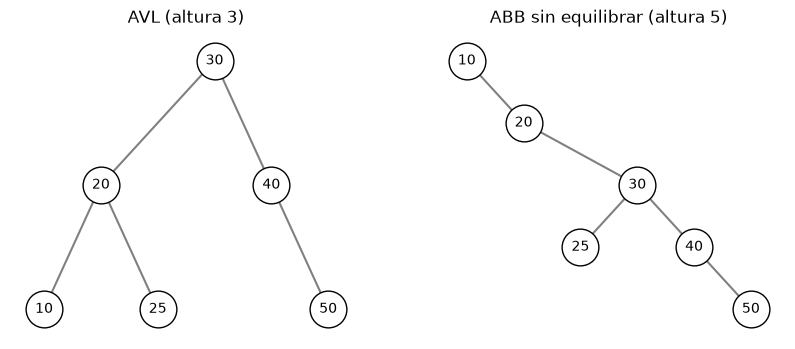

In [7]:
from collections import deque

import matplotlib.pyplot as plt


class Nodo:
    def __init__(self, valor):
        self.valor = valor
        self.izq = self.der = None


class ABB:
    # Iterativo: con claves ordenadas la profundidad llega a n y la recursión se desbordaría
    def __init__(self, valores=()):
        self.raiz = None
        for v in valores:
            self.insertar(v)

    def insertar(self, valor):
        if self.raiz is None:
            self.raiz = Nodo(valor)
            return
        nodo = self.raiz
        while nodo.valor != valor:
            lado = "izq" if valor < nodo.valor else "der"
            if getattr(nodo, lado) is None:
                setattr(nodo, lado, Nodo(valor))
                return
            nodo = getattr(nodo, lado)

    def __contains__(self, valor):
        nodo = self.raiz
        while nodo and nodo.valor != valor:
            nodo = nodo.izq if valor < nodo.valor else nodo.der
        return nodo is not None


def por_niveles(raiz):
    niveles, cola = [], deque([raiz] if raiz else [])
    while cola:
        nivel = []
        for _ in range(len(cola)):
            nodo = cola.popleft()
            nivel.append(nodo.valor)
            cola.extend(hijo for hijo in (nodo.izq, nodo.der) if hijo)
        niveles.append(nivel)
    return niveles


def dibujar(raiz, eje, titulo):
    posiciones = {}

    def colocar(nodo, profundidad):
        if nodo:
            colocar(nodo.izq, profundidad + 1)
            posiciones[nodo] = (len(posiciones), -profundidad)
            colocar(nodo.der, profundidad + 1)

    colocar(raiz, 0)
    for nodo, (x, y) in posiciones.items():
        for hijo in (nodo.izq, nodo.der):
            if hijo:
                eje.plot([x, posiciones[hijo][0]], [y, posiciones[hijo][1]], color="gray", zorder=1)
        eje.scatter(x, y, s=700, color="white", edgecolors="black", zorder=2)
        eje.text(x, y, nodo.valor, ha="center", va="center")
    eje.margins(0.12)
    eje.set_title(titulo)
    eje.axis("off")


claves = [10, 20, 30, 40, 50, 25]
arbol = AVL()
for clave in claves:
    antes = len(arbol.rotaciones)
    arbol.insertar(clave)
    nuevas = ", ".join(arbol.rotaciones[antes:]) or "ninguna"
    print(f"+{clave:<3} rotaciones: {nuevas:28} niveles: {por_niveles(arbol.raiz)}")
assert por_niveles(arbol.raiz) == [[30], [20, 40], [10, 25, 50]]

abb = ABB(claves)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
dibujar(arbol.raiz, ejes[0], f"AVL (altura {arbol.altura()})")
dibujar(abb.raiz, ejes[1], f"ABB sin equilibrar (altura {len(por_niveles(abb.raiz))})")
plt.show()

## 8. Borrar en un AVL

Borrar como en un árbol de búsqueda (si el nodo tiene dos hijos se copia en él su sucesor y se borra el sucesor) y reequilibrar cada nodo del camino de vuelta, lo que puede necesitar varias rotaciones. Devolver si el valor estaba. Comprobar contra `set` con inserciones y borrados aleatorios, verificando el invariante tras cada operación.

In [8]:
class AVL(AVL):
    def borrar(self, valor):
        antes = self.n
        self.raiz = self._borrar(self.raiz, valor)
        return self.n < antes

    def _borrar(self, nodo, valor):
        if nodo is None:
            return None
        if valor < nodo.valor:
            nodo.izq = self._borrar(nodo.izq, valor)
        elif valor > nodo.valor:
            nodo.der = self._borrar(nodo.der, valor)
        elif nodo.izq is None or nodo.der is None:
            self.n -= 1
            return nodo.izq or nodo.der
        else:
            sucesor = nodo.der
            while sucesor.izq:
                sucesor = sucesor.izq
            nodo.valor = sucesor.valor
            nodo.der = self._borrar(nodo.der, sucesor.valor)
        return self._equilibrar(nodo)


arbol = AVL(range(1, 16))
print("Antes:  ", por_niveles(arbol.raiz))
arbol.rotaciones.clear()
for x in (1, 2, 3, 4, 99):
    print(f"borrar({x}) → {arbol.borrar(x)}")
print("Después:", por_niveles(arbol.raiz))
print("Rotaciones:", arbol.rotaciones)

random.seed(8)
for _ in range(200):
    arbol, modelo = AVL(), set()
    for _ in range(100):
        x = random.randint(0, 40)
        if random.random() < 0.6:
            arbol.insertar(x)
            modelo.add(x)
        else:
            assert arbol.borrar(x) == (x in modelo)
            modelo.discard(x)
        comprobar_avl(arbol.raiz)
        assert len(arbol) == len(modelo)
    assert list(arbol) == sorted(modelo)
print("Comprobación correcta")

Antes:   [[8], [4, 12], [2, 6, 10, 14], [1, 3, 5, 7, 9, 11, 13, 15]]
borrar(1) → True
borrar(2) → True
borrar(3) → True
borrar(4) → True
borrar(99) → False
Después: [[8], [6, 12], [5, 7, 10, 14], [9, 11, 13, 15]]
Rotaciones: ['izquierda en 4']
Comprobación correcta


## 9. Altura logarítmica frente a un ABB

Insertar las claves $0, 1, \dots, n-1$ en orden en un AVL y en el `ABB` sin equilibrar, y en orden aleatorio en otro `ABB`. Dibujar la altura frente a $n$ junto a las cotas del AVL, $\log_2(n+1) \le h < 1{,}4405 \log_2(n+2) - 0{,}3277$, y medir cuánto se tarda en buscar todas las claves en cada árbol.

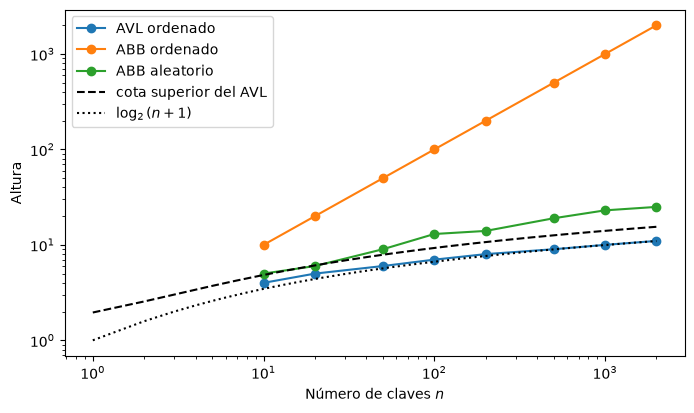

AVL ordenado   altura    11   buscar 2000 claves: 0.0007 s
ABB ordenado   altura  2000   buscar 2000 claves: 0.0596 s
ABB aleatorio  altura    25   buscar 2000 claves: 0.0010 s


In [9]:
import time

random.seed(9)
n_max = 2000
puntos = [10, 20, 50, 100, 200, 500, 1000, 2000]
arboles = {"AVL ordenado": AVL(), "ABB ordenado": ABB(), "ABB aleatorio": ABB()}
aleatorias = random.sample(range(n_max), n_max)
alturas = {nombre: [] for nombre in arboles}
for n in range(1, n_max + 1):
    arboles["AVL ordenado"].insertar(n - 1)
    arboles["ABB ordenado"].insertar(n - 1)
    arboles["ABB aleatorio"].insertar(aleatorias[n - 1])
    if n in puntos:
        for nombre, arbol in arboles.items():
            alturas[nombre].append(len(por_niveles(arbol.raiz)))

for n, h_avl, h_abb in zip(puntos, alturas["AVL ordenado"], alturas["ABB ordenado"]):
    assert math.log2(n + 1) <= h_avl < 1.4405 * math.log2(n + 2) - 0.3277
    assert h_abb == n

plt.figure(figsize=(8, 4.5))
for nombre, valores in alturas.items():
    plt.plot(puntos, valores, "o-", label=nombre)
x = range(1, n_max + 1)
plt.plot(x, [1.4405 * math.log2(n + 2) - 0.3277 for n in x], "k--", label="cota superior del AVL")
plt.plot(x, [math.log2(n + 1) for n in x], "k:", label="$\\log_2(n+1)$")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Número de claves $n$")
plt.ylabel("Altura")
plt.legend()
plt.show()

for nombre, arbol in arboles.items():
    inicio = time.perf_counter()
    assert all(clave in arbol for clave in range(n_max))
    print(f"{nombre:14} altura {alturas[nombre][-1]:5}   buscar {n_max} claves: {time.perf_counter() - inicio:.4f} s")

## 10. Grafo como clase

Representar un grafo con una lista de adyacencia: un diccionario que asocia a cada vértice otro diccionario `{vecino: peso}`. Crear `Grafo(dirigido=False)` con `agregar_vertice`, `agregar_arista(u, v, peso=1)` (en un grafo no dirigido se añade en los dos sentidos), `quitar_arista`, `vecinos`, `peso`, `vertices`, `aristas`, `grado_salida`, `grado_entrada`, `matriz` (matriz de adyacencia con los pesos), `__contains__`, `__len__` y `__repr__`. Probarlo con un grafo no dirigido ponderado (las islas con pesos de ejemplo) y con uno dirigido (asignaturas y sus requisitos).

In [10]:
class Grafo:
    def __init__(self, dirigido=False):
        self.dirigido = dirigido
        self.adyacencia = {}

    def agregar_vertice(self, v):
        self.adyacencia.setdefault(v, {})

    def agregar_arista(self, u, v, peso=1):
        self.agregar_vertice(u)
        self.agregar_vertice(v)
        self.adyacencia[u][v] = peso
        if not self.dirigido:
            self.adyacencia[v][u] = peso

    def quitar_arista(self, u, v):
        del self.adyacencia[u][v]
        if not self.dirigido:
            del self.adyacencia[v][u]

    def vecinos(self, v):
        return list(self.adyacencia[v])

    def peso(self, u, v):
        return self.adyacencia[u][v]

    def vertices(self):
        return list(self.adyacencia)

    def aristas(self):
        vistas, resultado = set(), []
        for u, vecinos in self.adyacencia.items():
            for v, peso in vecinos.items():
                if self.dirigido or (v, u) not in vistas:
                    vistas.add((u, v))
                    resultado.append((u, v, peso))
        return resultado

    def grado_salida(self, v):
        return len(self.adyacencia[v])

    def grado_entrada(self, v):
        return sum(v in vecinos for vecinos in self.adyacencia.values())

    def matriz(self):
        vertices = self.vertices()
        return [[self.adyacencia[u].get(v, 0) for v in vertices] for u in vertices]

    def __contains__(self, v):
        return v in self.adyacencia

    def __len__(self):
        return len(self.adyacencia)

    def __repr__(self):
        tipo = "dirigido" if self.dirigido else "no dirigido"
        return f"Grafo({tipo}, {len(self)} vértices, {len(self.aristas())} aristas)"


islas = Grafo()
for u, v, peso in [
    ("Gran Canaria", "Tenerife", 2), ("Gran Canaria", "Fuerteventura", 4), ("Fuerteventura", "Lanzarote", 1),
    ("Tenerife", "La Gomera", 1), ("Tenerife", "La Palma", 4), ("La Gomera", "El Hierro", 2),
    ("La Gomera", "La Palma", 3), ("Gran Canaria", "Lanzarote", 6),
]:
    islas.agregar_arista(u, v, peso)
print(islas)
print("Vecinos de Tenerife:", islas.vecinos("Tenerife"))
print("Grados:", {v: islas.grado_salida(v) for v in islas.vertices()})
for fila in islas.matriz():
    print(" ".join(f"{x:2}" for x in fila))

asignaturas = Grafo(dirigido=True)
for requisito, asignatura in [
    ("Programación", "Estructuras de datos"), ("Matemáticas", "Algoritmia"),
    ("Estructuras de datos", "Algoritmia"), ("Algoritmia", "Inteligencia artificial"),
    ("Estadística", "Inteligencia artificial"),
]:
    asignaturas.agregar_arista(requisito, asignatura)
print(asignaturas)
for v in asignaturas.vertices():
    print(f"{v:24} requisitos: {asignaturas.grado_entrada(v)}  abre: {asignaturas.grado_salida(v)}")

matriz = islas.matriz()
assert all(matriz[i][j] == matriz[j][i] for i in range(len(islas)) for j in range(len(islas)))
assert sum(islas.grado_salida(v) for v in islas.vertices()) == 2 * len(islas.aristas())
assert sum(asignaturas.grado_entrada(v) for v in asignaturas.vertices()) == len(asignaturas.aristas())
islas.quitar_arista("Gran Canaria", "Lanzarote")
assert "Lanzarote" not in islas.vecinos("Gran Canaria") and "Gran Canaria" not in islas.vecinos("Lanzarote")
print("Comprobación correcta")

Grafo(no dirigido, 7 vértices, 8 aristas)
Vecinos de Tenerife: ['Gran Canaria', 'La Gomera', 'La Palma']
Grados: {'Gran Canaria': 3, 'Tenerife': 3, 'Fuerteventura': 2, 'Lanzarote': 2, 'La Gomera': 3, 'La Palma': 2, 'El Hierro': 1}
 0  2  4  6  0  0  0
 2  0  0  0  1  4  0
 4  0  0  1  0  0  0
 6  0  1  0  0  0  0
 0  1  0  0  0  3  2
 0  4  0  0  3  0  0
 0  0  0  0  2  0  0
Grafo(dirigido, 6 vértices, 5 aristas)
Programación             requisitos: 0  abre: 1
Estructuras de datos     requisitos: 1  abre: 1
Matemáticas              requisitos: 0  abre: 1
Algoritmia               requisitos: 2  abre: 1
Inteligencia artificial  requisitos: 2  abre: 0
Estadística              requisitos: 0  abre: 1
Comprobación correcta


## 11. Recorridos y caminos mínimos

Ampliar `Grafo` con `bfs(origen)` (distancia en aristas a cada vértice alcanzable, en orden de visita), `dfs(origen)` (orden de visita en profundidad, iterativo), `dijkstra(origen)` (distancias y predecesores con `heapq`, $O((V+E)\log V)$ con pesos no negativos) y `camino(origen, destino)`. Comprobar Dijkstra contra Floyd–Warshall ($O(V^3)$) en grafos aleatorios dirigidos y no dirigidos, y que con todos los pesos a 1 coincide con el BFS.

In [11]:
import heapq


class Grafo(Grafo):
    def bfs(self, origen):
        distancia, cola = {origen: 0}, deque([origen])
        while cola:
            u = cola.popleft()
            for v in self.adyacencia[u]:
                if v not in distancia:
                    distancia[v] = distancia[u] + 1
                    cola.append(v)
        return distancia

    def dfs(self, origen):
        visitados, pila = [], [origen]
        while pila:
            u = pila.pop()
            if u not in visitados:
                visitados.append(u)
                pila.extend(reversed([v for v in self.adyacencia[u] if v not in visitados]))
        return visitados

    def dijkstra(self, origen):
        distancia, previo = {origen: 0}, {origen: None}
        monticulo = [(0, origen)]
        while monticulo:
            d, u = heapq.heappop(monticulo)
            if d > distancia[u]:
                continue
            for v, peso in self.adyacencia[u].items():
                if d + peso < distancia.get(v, math.inf):
                    distancia[v], previo[v] = d + peso, u
                    heapq.heappush(monticulo, (d + peso, v))
        return distancia, previo

    def camino(self, origen, destino):
        distancia, previo = self.dijkstra(origen)
        if destino not in distancia:
            return None, math.inf
        camino = [destino]
        while previo[camino[-1]] is not None:
            camino.append(previo[camino[-1]])
        return camino[::-1], distancia[destino]


def floyd_warshall(grafo):
    vertices = grafo.vertices()
    d = {u: {v: 0 if u == v else math.inf for v in vertices} for u in vertices}
    for u in vertices:
        for v, peso in grafo.adyacencia[u].items():
            d[u][v] = min(d[u][v], peso)
    for k in vertices:
        for i in vertices:
            for j in vertices:
                d[i][j] = min(d[i][j], d[i][k] + d[k][j])
    return d


islas = Grafo()
for u, v, peso in [
    ("Gran Canaria", "Tenerife", 2), ("Gran Canaria", "Fuerteventura", 4), ("Fuerteventura", "Lanzarote", 1),
    ("Tenerife", "La Gomera", 1), ("Tenerife", "La Palma", 4), ("La Gomera", "El Hierro", 2),
    ("La Gomera", "La Palma", 3),
]:
    islas.agregar_arista(u, v, peso)
print("BFS desde El Hierro:", islas.bfs("El Hierro"))
print("DFS desde El Hierro:", islas.dfs("El Hierro"))
print("Camino de El Hierro a Lanzarote:", islas.camino("El Hierro", "Lanzarote"))

random.seed(11)
for _ in range(300):
    dirigido = random.random() < 0.5
    grafo, unos = Grafo(dirigido), Grafo(dirigido)
    for v in range(random.randint(1, 9)):
        grafo.agregar_vertice(v)
        unos.agregar_vertice(v)
    for _ in range(random.randint(0, 20)):
        u, v = random.sample(range(len(grafo)), 2) if len(grafo) > 1 else (0, 0)
        if u != v:
            grafo.agregar_arista(u, v, random.randint(1, 20))
            unos.agregar_arista(u, v)
    d = floyd_warshall(grafo)
    for origen in grafo.vertices():
        distancia, _ = grafo.dijkstra(origen)
        assert distancia == {v: x for v, x in d[origen].items() if x < math.inf}
        for destino in distancia:
            camino, total = grafo.camino(origen, destino)
            assert total == sum(grafo.peso(a, b) for a, b in zip(camino, camino[1:]))
        assert unos.bfs(origen) == unos.dijkstra(origen)[0]
        assert set(grafo.dfs(origen)) == set(grafo.bfs(origen))
print("Comprobación correcta")

BFS desde El Hierro: {'El Hierro': 0, 'La Gomera': 1, 'Tenerife': 2, 'La Palma': 2, 'Gran Canaria': 3, 'Fuerteventura': 4, 'Lanzarote': 5}
DFS desde El Hierro: ['El Hierro', 'La Gomera', 'Tenerife', 'Gran Canaria', 'Fuerteventura', 'Lanzarote', 'La Palma']
Camino de El Hierro a Lanzarote: (['El Hierro', 'La Gomera', 'Tenerife', 'Gran Canaria', 'Fuerteventura', 'Lanzarote'], 10)
Comprobación correcta


## 12. Banco de pruebas contra fuerza bruta

Escribir `probar(estructura, modelo, operaciones, pasos, semilla)`, que aplique la misma secuencia aleatoria de operaciones a una estructura y a un modelo ingenuo con los mismos métodos (una lista o un `set` envueltos en una clase) y compruebe que siempre devuelven lo mismo. Usarla con `Fenwick`, `ArbolSegmentos`, `ArbolPerezoso` y `AVL`. Después, medir cuánto se tarda en hacer $10^4$ consultas de suma de rango y asignaciones sobre $10^5$ elementos con una lista y con cada árbol.

In [12]:
class ListaIngenua:
    def __init__(self, valores):
        self.a = list(valores)

    def rango(self, i, j):
        return sum(self.a[i:j])

    consultar = suma = rango

    def minimo(self, i, j):
        return min(self.a[i:j], default=math.inf)

    def valor(self, i):
        return self.a[i]

    def asignar(self, i, x):
        self.a[i] = x

    def sumar_rango(self, i, j, delta):
        for k in range(i, j):
            self.a[k] += delta


class ConjuntoIngenuo:
    def __init__(self):
        self.s = set()

    def insertar(self, x):
        self.s.add(x)

    def borrar(self, x):
        estaba = x in self.s
        self.s.discard(x)
        return estaba

    def __contains__(self, x):
        return x in self.s

    def __len__(self):
        return len(self.s)

    def __iter__(self):
        return iter(sorted(self.s))


def probar(estructura, modelo, operaciones, pasos=3000, semilla=0):
    rng = random.Random(semilla)
    for _ in range(pasos):
        nombre, argumentos = rng.choice(operaciones)
        args = argumentos(rng)
        esperado = getattr(modelo, nombre)(*args)
        obtenido = getattr(estructura, nombre)(*args)
        assert obtenido == esperado, (nombre, args, obtenido, esperado)


n = 200
random.seed(12)
valores = [random.randint(-50, 50) for _ in range(n)]


def tramo(rng):
    j = rng.randint(0, n)
    return rng.randint(0, j), j


operaciones = {
    "posicion": lambda rng: (rng.randrange(n),),
    "asignacion": lambda rng: (rng.randrange(n), rng.randint(-50, 50)),
    "tramo_delta": lambda rng: (*tramo(rng), rng.randint(-20, 20)),
    "clave": lambda rng: (rng.randint(0, 300),),
}
casos = [
    ("Fenwick", Fenwick(valores), ListaIngenua(valores),
     [("rango", tramo), ("valor", operaciones["posicion"]), ("asignar", operaciones["asignacion"])]),
    ("ArbolSegmentos", ArbolSegmentos(valores, operator.add, 0), ListaIngenua(valores),
     [("consultar", tramo), ("asignar", operaciones["asignacion"])]),
    ("ArbolPerezoso", ArbolPerezoso(valores), ListaIngenua(valores),
     [("suma", tramo), ("minimo", tramo), ("sumar_rango", operaciones["tramo_delta"])]),
    ("AVL", AVL(), ConjuntoIngenuo(),
     [("insertar", operaciones["clave"]), ("borrar", operaciones["clave"]),
      ("__contains__", operaciones["clave"]), ("__len__", lambda rng: ())]),
]
for semilla, (nombre, estructura, modelo, ops) in enumerate(casos):
    probar(estructura, modelo, ops, semilla=semilla)
    print(f"{nombre:15} 3000 operaciones aleatorias correctas")
_, avl, conjunto, _ = casos[-1]
comprobar_avl(avl.raiz)
assert list(avl) == list(conjunto)

n, q = 10**5, 10**4
rng = random.Random(13)
valores = [rng.randint(-50, 50) for _ in range(n)]
peticiones = []
for _ in range(q):
    i, j = sorted(rng.sample(range(n + 1), 2))
    peticiones.append((rng.random() < 0.5, i, j, rng.randint(-50, 50)))


def medir(consultar, asignar):
    inicio = time.perf_counter()
    resultados = [consultar(i, j) if es_consulta else asignar(i, x) for es_consulta, i, j, x in peticiones]
    return time.perf_counter() - inicio, resultados


lista = list(valores)
fenwick = Fenwick(valores)
segmentos = ArbolSegmentos(valores, operator.add, 0)
perezoso = ArbolPerezoso(valores)
tiempos = {
    "Lista": medir(lambda i, j: sum(lista[i:j]), lista.__setitem__),
    "Fenwick": medir(fenwick.rango, fenwick.asignar),
    "ArbolSegmentos": medir(segmentos.consultar, segmentos.asignar),
    "ArbolPerezoso": medir(perezoso.suma, lambda i, x: perezoso.sumar_rango(i, i + 1, x - perezoso.suma(i, i + 1))),
}
referencia = tiempos["Lista"][1]
for nombre, (segundos, resultados) in tiempos.items():
    assert resultados == referencia
    print(f"{nombre:15} {segundos:.3f} s")

Fenwick         3000 operaciones aleatorias correctas
ArbolSegmentos  3000 operaciones aleatorias correctas
ArbolPerezoso   3000 operaciones aleatorias correctas
AVL             3000 operaciones aleatorias correctas


Lista           2.668 s
Fenwick         0.030 s
ArbolSegmentos  0.033 s
ArbolPerezoso   0.148 s
